# 02 · Slang

Part 2 of the claim: *the vibe isn't in the words people search with.*
People search "boujee". Reviews say "fancy".

1. Gap table: slang vs. plain words (the headline)
2. Urban Dictionary slang lexicon
3. Which slang shows up in reviews

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from tqdm.auto import tqdm

from vibecheck.filter_sf import PROCESSED_DIR, REVIEWS_OUT
from vibecheck.lexicon import (
    GAP_QUERIES,
    UD_CSV,
    build_slang_lexicon,
    find_terms,
    gap_table,
    load_ud_definitions,
)
from vibecheck.plots import MUTED, SINGLE_COLOR, use_style
from vibecheck.report import write_section

use_style()
reviews = pd.read_parquet(REVIEWS_OUT)
print(f"{len(reviews):,} reviews, {reviews['gmap_id'].nunique():,} places")

212,176 reviews, 5,669 places


## 1. Gap table

Words picked before counting. Every row is shown.

In [2]:
gap = gap_table(reviews)
gap

,query,plain meaning,reviews (slang),reviews (plain),places (slang),places (plain)
0,boujee,"fancy, upscale, classy, elegant, luxurious",32,1582,32,1154
1,lowkey,"low-key, low key, laid-back, unpretentious, un...",14,548,14,478
2,vibey,"atmosphere, ambiance, ambience",763,10919,628,3530
3,aesthetic,"beautiful, gorgeous, stylish, decor",93,4171,91,2236
4,chill,"relaxed, relaxing, calm, mellow, laid-back",1418,1365,965,1035
5,bussin,"delicious, tasty, flavorful",5,31683,5,4949
6,slaps,"delicious, tasty, flavorful",24,31683,23,4949
7,goated,"the best, excellent, outstanding",0,22461,0,4969
8,poppin,"lively, bustling, busy, packed",29,4045,27,2539
9,instagrammable,"photogenic, picturesque",11,20,10,19


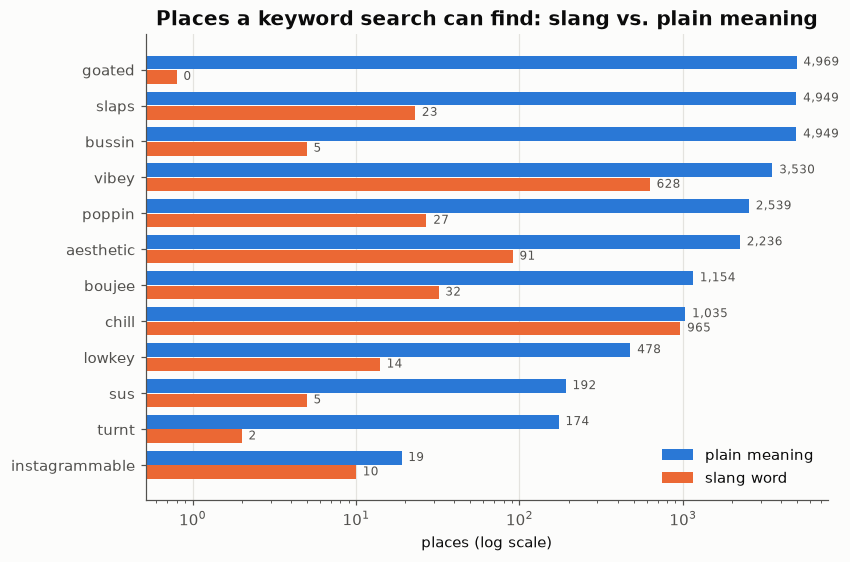

In [3]:
# Places keyword search can reach with the slang word vs. with its plain meaning (log scale).
SLANG_COLOR, PLAIN_COLOR = "#eb6834", "#2a78d6"  # validated categorical slots 2 and 1
order = gap.sort_values("places (plain)")
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(y + 0.2, order["places (plain)"].clip(lower=0.8), height=0.38, color=PLAIN_COLOR, label="plain meaning")
ax.barh(y - 0.2, order["places (slang)"].clip(lower=0.8), height=0.38, color=SLANG_COLOR, label="slang word")
for i, (s, p) in enumerate(zip(order["places (slang)"], order["places (plain)"], strict=True)):
    ax.text(max(s, 0.8) * 1.1, i - 0.2, f"{s:,}", va="center", color=MUTED, fontsize=8)
    ax.text(p * 1.1, i + 0.2, f"{p:,}", va="center", color=MUTED, fontsize=8)
ax.set_yticks(y, order["query"])
ax.set_xscale("log")
ax.set(title="Places a keyword search can find: slang vs. plain meaning", xlabel="places (log scale)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.savefig("../reports/gap_chart.png")
plt.show()

## 2. Urban Dictionary lexicon

Rules (in `lexicon.py`):

- a definition with ≥100 upvotes and ≥70% upvote ratio
- single words: rare in everyday English (0 < Zipf < 3)
- two-word phrases like "low key": only if UD also has them as one word ("lowkey")
- no terms whose definitions look offensive or describe a name

Votes stop in 2016, so no "rizz".

In [4]:
definitions = load_ud_definitions(UD_CSV)
lexicon = build_slang_lexicon(definitions)
lexicon.to_parquet(PROCESSED_DIR / "slang_lexicon.parquet", index=False)
print(f"{len(definitions):,} well-voted definitions -> {len(lexicon):,} slang terms "
      f"({lexicon['term'].str.contains(' ').sum():,} two-word phrases)")

# What UD says about our query words. This is the "find meaning" step of query expansion.
best = definitions.assign(term=definitions["word"].str.lower()).sort_values("up_votes", ascending=False)
meanings = best.drop_duplicates("term").set_index("term").reindex(list(GAP_QUERIES))
meanings["definition"] = meanings["definition"].str.replace(";;", " ").str.slice(0, 140)
meanings[["up_votes", "definition"]]

108,395 well-voted definitions -> 12,384 slang terms (595 two-word phrases)


,up_votes,definition
term,,
boujee,NaN,NaN
lowkey,1947.0,To keep things secret
vibey,NaN,NaN
aesthetic,1453.0,ADJECTIVE: 1. Beautiful. 2. Sensitive to o...
chill,3996.0,"1. to calm down 2. cool, tight, wicked, sick..."
bussin,NaN,NaN
slaps,920.0,crackin songs from the bay area
goated,NaN,NaN
poppin,1051.0,to get (something) started


Two lessons. The 2016 dump has no entry for newer slang, so we also need the live UD API. And the
top-voted definition often has the wrong sense ("lowkey" = "to keep things secret"), so we have to
pick the definition that fits the query.

In [5]:
missing = meanings.index[meanings["up_votes"].isna()].tolist()
print("not in the 2016 dump:", ", ".join(missing))

not in the 2016 dump: boujee, vibey, bussin, goated, instagrammable


## 3. Can the lexicon spot slang in reviews?

spaCy splits sentences, then we look up each word and word pair.
Spoiler: the top hits are mostly food words and typos. Rare isn't the same as slang, so we use the
lexicon to explain slang in *queries*, not to find it in reviews.

In [6]:
nlp = spacy.load("en_core_web_sm", exclude=["parser", "ner", "lemmatizer", "tagger", "attribute_ruler"])
nlp.enable_pipe("senter")
terms = set(lexicon["term"])

n_sentences, n_with_slang, term_counts = 0, 0, Counter()
for doc in tqdm(nlp.pipe(reviews["text"], batch_size=512), total=len(reviews), desc="sentences"):
    for sent in doc.sents:
        found = find_terms(sent.text, terms)
        n_sentences += 1
        n_with_slang += bool(found)
        term_counts.update(set(found))

slang_share = n_with_slang / n_sentences
print(f"{n_sentences:,} sentences, {slang_share:.1%} contain at least one Urban Dictionary slang term")

sentences:   0%|          | 0/212176 [00:00<?, ?it/s]

563,394 sentences, 4.2% contain at least one Urban Dictionary slang term


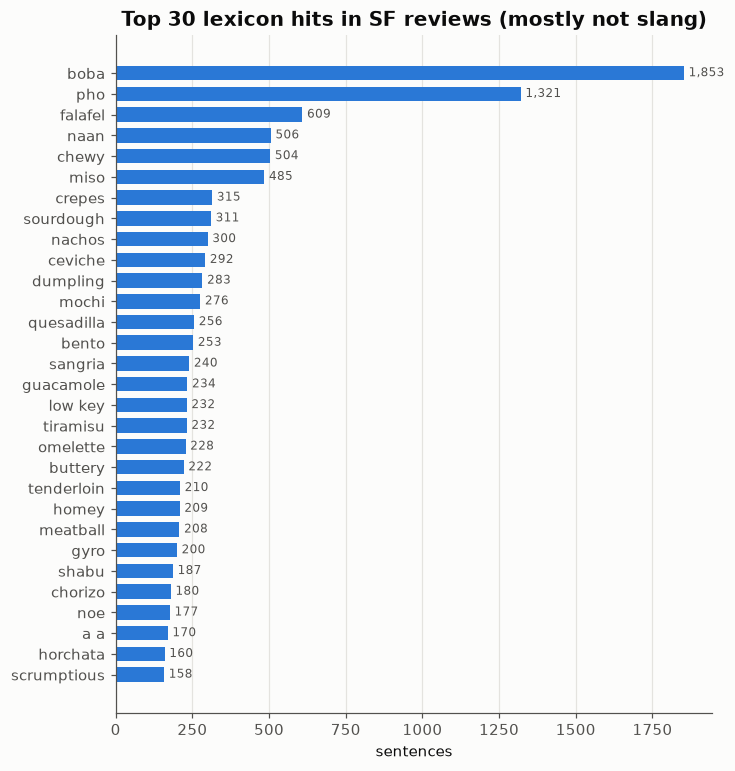

In [7]:
top30 = pd.DataFrame(term_counts.most_common(30), columns=["term", "sentences"])
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(top30["term"][::-1], top30["sentences"][::-1], color=SINGLE_COLOR, height=0.7)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3, color=MUTED, fontsize=8)
ax.set(title="Top 30 lexicon hits in SF reviews (mostly not slang)", xlabel="sentences")
ax.grid(axis="y", visible=False)
fig.savefig("../reports/top_slang.png")
plt.show()

## 4. Save to `numbers.md`

In [8]:
md = f"""## Slang: the vibe is not in the words people search with (notebook 02)

Words picked before counting. All rows shown.

{gap.to_markdown(index=False, floatfmt=",.0f")}

- Urban Dictionary lexicon: {len(lexicon):,} slang terms ({lexicon['term'].str.contains(' ').sum():,} two-word phrases), from {len(definitions):,} well-voted definitions.
- Not in the 2016 dump: {", ".join(missing)}. We need the live UD API for these.
- Top-voted meanings can miss the sense: lowkey = "{meanings.loc["lowkey", "definition"]}". Pick the one that fits the query.
- {n_sentences:,} review sentences (spaCy); {slang_share:.1%} contain at least one lexicon term.

30 most common lexicon hits in reviews. Mostly food words and typos, so the lexicon is for queries, not reviews:
{", ".join(f"{t} ({n:,})" for t, n in top30.itertuples(index=False))}
"""
write_section("slang", md)
print(md)

## Slang: the vibe is not in the words people search with (notebook 02)

Words picked before counting. All rows shown.

| query          | plain meaning                                           |   reviews (slang) |   reviews (plain) |   places (slang) |   places (plain) |
|:---------------|:--------------------------------------------------------|------------------:|------------------:|-----------------:|-----------------:|
| boujee         | fancy, upscale, classy, elegant, luxurious              |                32 |              1582 |               32 |             1154 |
| lowkey         | low-key, low key, laid-back, unpretentious, understated |                14 |               548 |               14 |              478 |
| vibey          | atmosphere, ambiance, ambience                          |               763 |             10919 |              628 |             3530 |
| aesthetic      | beautiful, gorgeous, stylish, decor                     |                93 |         